# Tune an IMSTE embedding on an MNIST-family dataset

Choose `MNIST`, `Fashion-MNIST`, or `Kuzushiji-MNIST`, then select `fast` or `complete` in the settings cell. Fast mode uses Bayesian optimization for 40 trials. Complete mode searches all fourteen parameters using an explicit grid of 16,384 possible configurations, capped by the user-defined `N_TRIALS` budget.

Each trial fits the estimator for its default 200 epochs and scores 5-fold k-NN accuracy (60%) plus robust spatial coverage (40%). Install the optional optimizer with `python -m pip install 'imste[tuning]'` if needed (required for fast mode).


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / 'notebooks' / 'src' / 'digits_sweep.py').is_file()
)
sys.path.insert(0, str(repo_root / 'notebooks' / 'src'))
sys.path.insert(0, str(repo_root))

from digits_sweep import (
    MNIST_FAMILY_DATASETS,
    load_mnist_per_class_data,
    load_mnist_family_data,
    make_live_tuning_display,
    plot_mnist_embedding,
)
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.visualization import render_datashader_embedding


## Choose and prepare the data

Choose one of `MNIST_FAMILY_DATASETS` below. Sampling is deterministic and balanced; the default is 200 images per class. The helper uses the project cache when available and downloads the selected dataset otherwise.


In [2]:
DATASET = 'Kuzushiji-MNIST'  # Also: 'MNIST' or 'Kuzushiji-MNIST' or 'Fashion-MNIST'
SAMPLES_PER_CLASS = 200
RANDOM_STATE = 42

if DATASET not in MNIST_FAMILY_DATASETS:
    raise ValueError(f'DATASET must be one of {MNIST_FAMILY_DATASETS}.')

X, y, data_info = load_mnist_per_class_data(
    samples_per_class=SAMPLES_PER_CLASS,
    random_state=RANDOM_STATE,
    dataset_name=DATASET,
)
print(
    f"Loaded {len(X):,} images from {data_info['dataset']} ({SAMPLES_PER_CLASS} per class; {X.shape[1]} pixel features)."
)
display(data_info['class_counts'].to_frame())


Loaded 2,000 images from Kuzushiji-MNIST (200 per class; 784 pixel features).


,images
0,200
1,200
2,200
3,200
4,200
5,200
6,200
7,200
8,200
9,200


## Set up the search

Both modes use `mapper.tune()` and its Bayesian sampler. `default` uses the core default search space; `custom` uses the parameter space below. In either space, a two-number tuple gives bounds and a list gives explicit candidate values.

In [ ]:
SEARCH_MODE = 'custom'  # Choose: 'default' or 'custom'
N_TRIALS = 40  # User-defined maximum number of search trials
K = 5
COVERAGE_WEIGHT = 0.2

CUSTOM_SEARCH_SPACE = {
    'n_msts': (2, 30),
    'negative_ratio': (1, 10),
    'gravity_strength': (0.05, 1.0),
    'mean_shift_iterations': (0, 5),
    'lambda_rep': (0.25, 0.75),
    'gravity_resolution': (0.5, 2.0),
    'include_knn_attraction': [False, True],
    'logistic_margin': (0.25, 2.0),
    'logistic_temperature': (0.1, 1.0),
}

if SEARCH_MODE not in {'default', 'custom'}:
    raise ValueError("SEARCH_MODE must be either 'default' or 'custom'.")

mapper = IteratedMinimumSpanningTreeEmbedder(
    random_state=RANDOM_STATE,
    device='auto',
)


## Watch intermediate results

The table reports accuracy, spatial coverage, and the weighted objective after every trial. The plot updates when a trial improves the combined objective. Complete mode reports progress for every grid combination.


**Trial 40/40** — accuracy: 0.649; coverage: 0.125; objective: 0.545; best objective: 0.643

,accuracy,coverage,objective,best objective,n_msts,negative_ratio,gravity_strength,mean_shift_iterations,lambda_rep,gravity_resolution,include_knn_attraction,logistic_margin,logistic_temperature
trial,,,,,,,,,,,,,
1,0.6925,0.373860,0.628772,0.628772,30,10,0.0,0,0.75,2.0,False,1.0,0.50
2,0.5550,0.125814,0.469163,0.628772,3,1,0.0,5,0.25,2.0,True,0.5,0.50
3,0.6615,0.025771,0.534354,0.628772,30,10,1.0,0,0.25,0.5,False,1.0,0.25
4,0.7065,0.014334,0.568067,0.628772,3,1,1.0,5,0.25,0.5,False,0.5,0.25
5,0.6925,0.129992,0.579998,0.628772,3,1,0.0,5,0.25,0.5,False,0.5,0.25
6,0.7135,0.040416,0.578883,0.628772,30,10,1.0,0,0.25,2.0,False,1.0,0.50
7,0.7525,0.055707,0.613141,0.628772,30,10,1.0,0,0.75,2.0,False,0.5,0.25
8,0.6115,0.104970,0.510194,0.628772,3,1,0.0,5,0.25,2.0,True,1.0,0.25
9,0.7070,0.017809,0.569162,0.628772,3,10,1.0,5,0.25,0.5,False,1.0,0.25


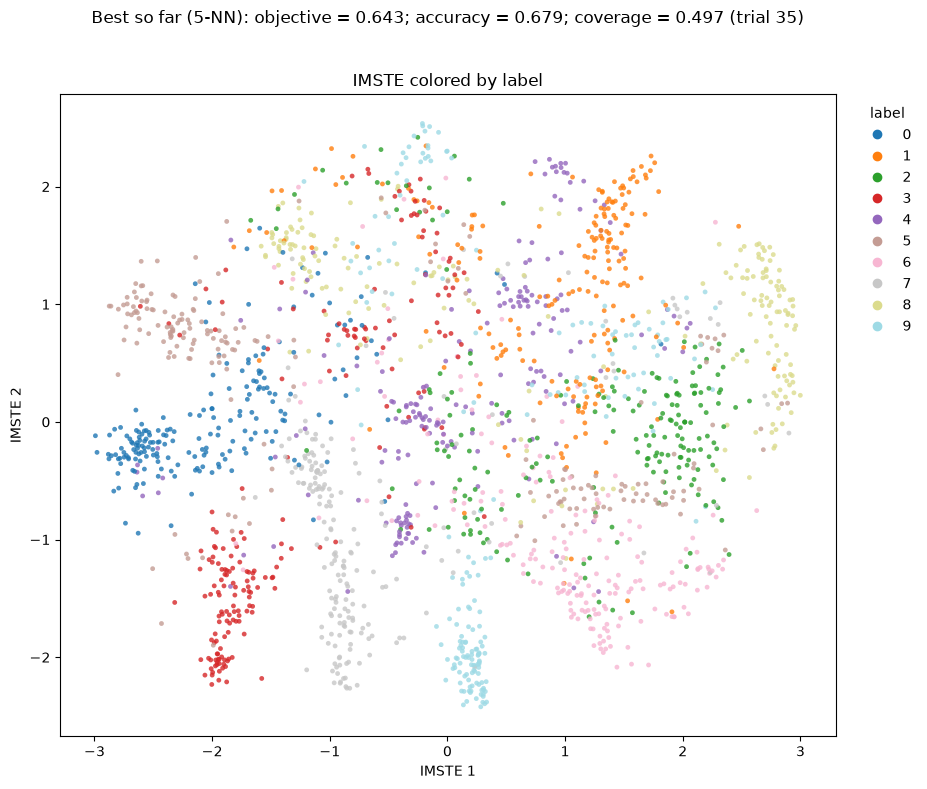

Complete search and final refit completed in 2.1 minutes


In [4]:
if isinstance(N_TRIALS, (bool, np.bool_)) or not isinstance(N_TRIALS, (int, np.integer)) or N_TRIALS < 1:
    raise ValueError('N_TRIALS must be a positive integer.')
show_trial, trial_rows = make_live_tuning_display(
    y, k=K, n_samples=N_TRIALS, figsize=(12, 8)
)

started = time.perf_counter()
search = mapper.tune(
    X, y,
    search_space=CUSTOM_SEARCH_SPACE if SEARCH_MODE == 'custom' else None,
    k=K,
    n_samples=N_TRIALS,
    n_initial_points=min(20, N_TRIALS),
    coverage_weight=COVERAGE_WEIGHT,
    trial_callback=show_trial,
)
elapsed = time.perf_counter() - started
print(f'{SEARCH_MODE.title()} search and final refit completed in {elapsed / 60:.1f} minutes')


## Best result

The estimator is refitted on all selected images using the configuration with the highest weighted objective. The returned result retains the separate accuracy, coverage, and combined scores.

Best 5-fold 5-NN accuracy: 0.679
Best spatial coverage: 0.497
Best combined objective: 0.643


,best value
n_msts,30
negative_ratio,1
gravity_strength,0.0
mean_shift_iterations,0
lambda_rep,0.75
gravity_resolution,2.0
include_knn_attraction,False
logistic_margin,0.5
logistic_temperature,0.25


(<Figure size 1200x800 with 1 Axes>,
 array([[<Axes: title={'center': 'IMSTE colored by label'}, xlabel='IMSTE 1', ylabel='IMSTE 2'>]],
       dtype=object))

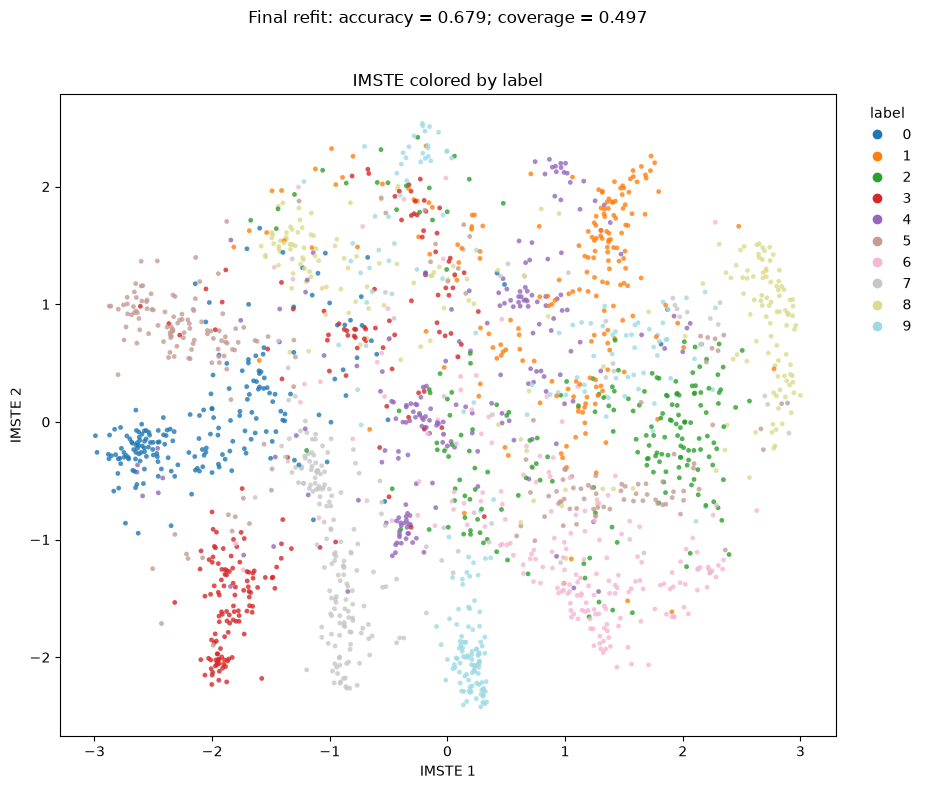

In [5]:
print(f"Best 5-fold {search.k}-NN accuracy: {search.best_accuracy:.3f}")
print(f"Best spatial coverage: {search.best_coverage:.3f}")
print(f"Best combined objective: {search.best_objective:.3f}")
display(pd.Series(search.best_params, name='best value').to_frame())
plot_mnist_embedding(
    mapper.embedding_, y,
    title=(
        f'Final refit: accuracy = {search.best_accuracy:.3f}; '
        f'coverage = {search.best_coverage:.3f}'
    ),
    figsize=(12, 8),
)

## Refit on the full dataset

After tuning on the selected balanced sample, load every row from the chosen dataset and fit the selected parameters again. The live search scores above are measured on the tuning sample; this final embedding uses the full dataset.

Refit on 70,000 Kuzushiji-MNIST images in 0.4 minutes


,images
0,7000
1,7000
2,7000
3,7000
4,7000
5,7000
6,7000
7,7000
8,7000
9,7000


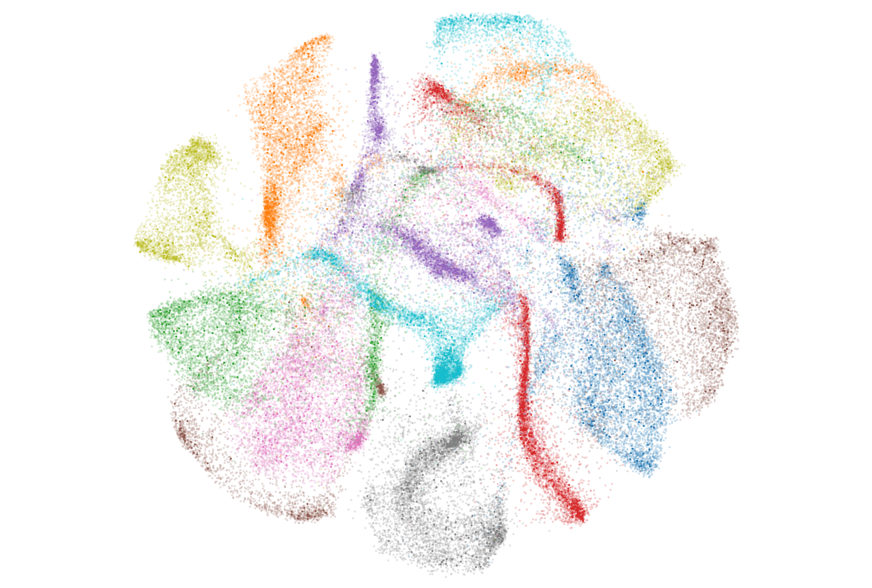

In [6]:
X_full, y_full, full_data_info = load_mnist_family_data(DATASET)
mapper.set_params(**search.best_params)

started = time.perf_counter()
mapper.fit(X_full)
elapsed = time.perf_counter() - started
print(
    f"Refit on {len(X_full):,} {full_data_info['dataset']} images "
    f"in {elapsed / 60:.1f} minutes"
)
display(full_data_info['class_counts'].to_frame())
s = 1.2
full_image = render_datashader_embedding(
    mapper.embedding_, y_full,
    width=int(1800*s), height=int(1200*s),
    preserve_aspect=True, min_alpha=60, spread_px=2, draw_border=False,
)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(full_image.to_pil())
ax.set_axis_off()
display(fig)
plt.close(fig)